In [122]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.preprocessing import OneHotEncoder,StandardScaler
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,recall_score,classification_report,confusion_matrix,precision_score

In [123]:
df=pd.read_csv('/home/backup/ml_datasets/adult_income.csv')
print(df)
print(df.isnull().sum())

        age     workclass    fnlwgt     education  education-num  \
0      25.0       Private  226802.0          11th            7.0   
1      38.0       Private   89814.0       HS-grad            9.0   
2      28.0     Local-gov  336951.0    Assoc-acdm           12.0   
3      44.0       Private  160323.0  Some-college           10.0   
4      18.0           NaN  103497.0  Some-college           10.0   
...     ...           ...       ...           ...            ...   
48837  27.0       Private  257302.0    Assoc-acdm           12.0   
48838  40.0       Private  154374.0       HS-grad            9.0   
48839  58.0       Private  151910.0       HS-grad            9.0   
48840  22.0       Private  201490.0       HS-grad            9.0   
48841  52.0  Self-emp-inc  287927.0       HS-grad            9.0   

           marital-status         occupation relationship   race     sex  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Fa

In [124]:
x=df.drop('class',axis=1)
print(x)
y=df['class']
print(y)
df.head()

        age     workclass    fnlwgt     education  education-num  \
0      25.0       Private  226802.0          11th            7.0   
1      38.0       Private   89814.0       HS-grad            9.0   
2      28.0     Local-gov  336951.0    Assoc-acdm           12.0   
3      44.0       Private  160323.0  Some-college           10.0   
4      18.0           NaN  103497.0  Some-college           10.0   
...     ...           ...       ...           ...            ...   
48837  27.0       Private  257302.0    Assoc-acdm           12.0   
48838  40.0       Private  154374.0       HS-grad            9.0   
48839  58.0       Private  151910.0       HS-grad            9.0   
48840  22.0       Private  201490.0       HS-grad            9.0   
48841  52.0  Self-emp-inc  287927.0       HS-grad            9.0   

           marital-status         occupation relationship   race     sex  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Fa

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25.0,Private,226802.0,11th,7.0,Never-married,Machine-op-inspct,Own-child,Black,Male,0.0,0.0,40.0,United-States,<=50K
1,38.0,Private,89814.0,HS-grad,9.0,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.0,0.0,50.0,United-States,<=50K
2,28.0,Local-gov,336951.0,Assoc-acdm,12.0,Married-civ-spouse,Protective-serv,Husband,White,Male,0.0,0.0,40.0,United-States,>50K
3,44.0,Private,160323.0,Some-college,10.0,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688.0,0.0,40.0,United-States,>50K
4,18.0,NaN,103497.0,Some-college,10.0,Never-married,NaN,Own-child,White,Female,0.0,0.0,30.0,United-States,<=50K


In [125]:
y=df['class'].map({'<=50K':0,'>50K':1})
print("\nTarget values")
print(y.value_counts())


Target values
0    37155
1    11687
Name: class, dtype: int64


In [126]:
#identify numerical and categorical columns
numerical_features = x.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = x.select_dtypes(include=["category","object"]).columns.tolist()
print("\nNumerical features:")
print(numerical_features)
print("\nCategorical features:")
print(categorical_features)


Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [127]:
# Numerical columns
for column in numerical_features:
    x[column]=x[column].fillna(x[column].median())
print(x[column])
# Categorical columns
for column in categorical_features:
    x[column]=x[column].fillna(x[column].mode()[0])
print(x[column])

0        40.0
1        50.0
2        40.0
3        40.0
4        30.0
         ... 
48837    38.0
48838    40.0
48839    40.0
48840    20.0
48841    40.0
Name: hours-per-week, Length: 48842, dtype: float64
0        United-States
1        United-States
2        United-States
3        United-States
4        United-States
             ...      
48837    United-States
48838    United-States
48839    United-States
48840    United-States
48841    United-States
Name: native-country, Length: 48842, dtype: object


In [128]:
encoder=OneHotEncoder(handle_unknown="ignore",sparse=False)
x_categoriical=encoder.fit_transform(x[categorical_features])
#Get encoded feature names
encoded_feature_names=(encoder.get_feature_names(categorical_features))
# Convert encoded data into Dataframe
x_categoriical=pd.DataFrame(x_categoriical,columns=encoded_feature_names,index=x.index)
print("\nEncoded categorical data shape: ",x_categoriical.shape)


Encoded categorical data shape:  (48842, 99)


In [129]:
# scale numerical variables
scaler=StandardScaler()
x_numerical=scaler.fit_transform(x[numerical_features])
# convert numerical data into Dataframe
x_numerical=pd.DataFrame(x_numerical,columns=numerical_features,index=x.index)

In [130]:
# combine numerical and categorical data
x_processed = pd.concat([x_numerical,x_categoriical],axis=1)
print("\nFinal processed dataset shape:",x_processed.shape)


Final processed dataset shape: (48842, 105)


In [131]:
# Train test split
x_train,x_test,y_train,y_test=train_test_split(x_processed,y,test_size=0.2,random_state=42,stratify=y)
print("\nTraining samples",x_train.shape[0])
print("\nTesting samples",x_test.shape[0])


Training samples 39073

Testing samples 9769


In [132]:
model=LogisticRegression(max_iter=1000,random_state=42)
model.fit(x_train,y_train)
print("Training completed")
y_pred=model.predict(x_test)
print(y_pred)

Training completed
[0 0 1 ... 1 0 0]


In [133]:
print("\nMETRICS OF LOGISTIC REGRESSION\n")
print(f"Accuracy Score: {accuracy_score(y_test,y_pred):.4f}")
print(f"Precision Score: {precision_score(y_test,y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test,y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test,y_pred):.4f}")
print(f"Confusion matrix: \n{confusion_matrix(y_test,y_pred)}")
print("\n CLASSIFICATION MATRIX")
print(classification_report(y_test,y_pred))


METRICS OF LOGISTIC REGRESSION

Accuracy Score: 0.8523
Precision Score: 0.7410
Recall Score: 0.5885
F1 Score: 0.6560
Confusion matrix: 
[[6950  481]
 [ 962 1376]]

 CLASSIFICATION MATRIX
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7431
           1       0.74      0.59      0.66      2338

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.85      0.85      0.85      9769



In [134]:
tree=DecisionTreeClassifier(criterion='entropy',max_depth=4)
tree.fit(x_train,y_train)
y_predtree=tree.predict(x_test)
print(y_predtree)

[0 0 0 ... 1 0 0]


In [135]:
print("\nMETRICS OF DECISION TREE\n")
print(f"Accuracy Score: {accuracy_score(y_test,y_predtree):.4f}")
print(f"Precision Score: {precision_score(y_test,y_predtree):.4f}")
print(f"Recall Score: {recall_score(y_test,y_predtree):.4f}")
print(f"F1 Score: {f1_score(y_test,y_predtree):.4f}")
print(f"Confusion matrix: \n{confusion_matrix(y_test,y_predtree)}")
print("\n CLASSIFICATION MATRIX")
print(classification_report(y_test,y_predtree))


METRICS OF DECISION TREE

Accuracy Score: 0.8456
Precision Score: 0.7433
Recall Score: 0.5423
F1 Score: 0.6271
Confusion matrix: 
[[6993  438]
 [1070 1268]]

 CLASSIFICATION MATRIX
              precision    recall  f1-score   support

           0       0.87      0.94      0.90      7431
           1       0.74      0.54      0.63      2338

    accuracy                           0.85      9769
   macro avg       0.81      0.74      0.76      9769
weighted avg       0.84      0.85      0.84      9769



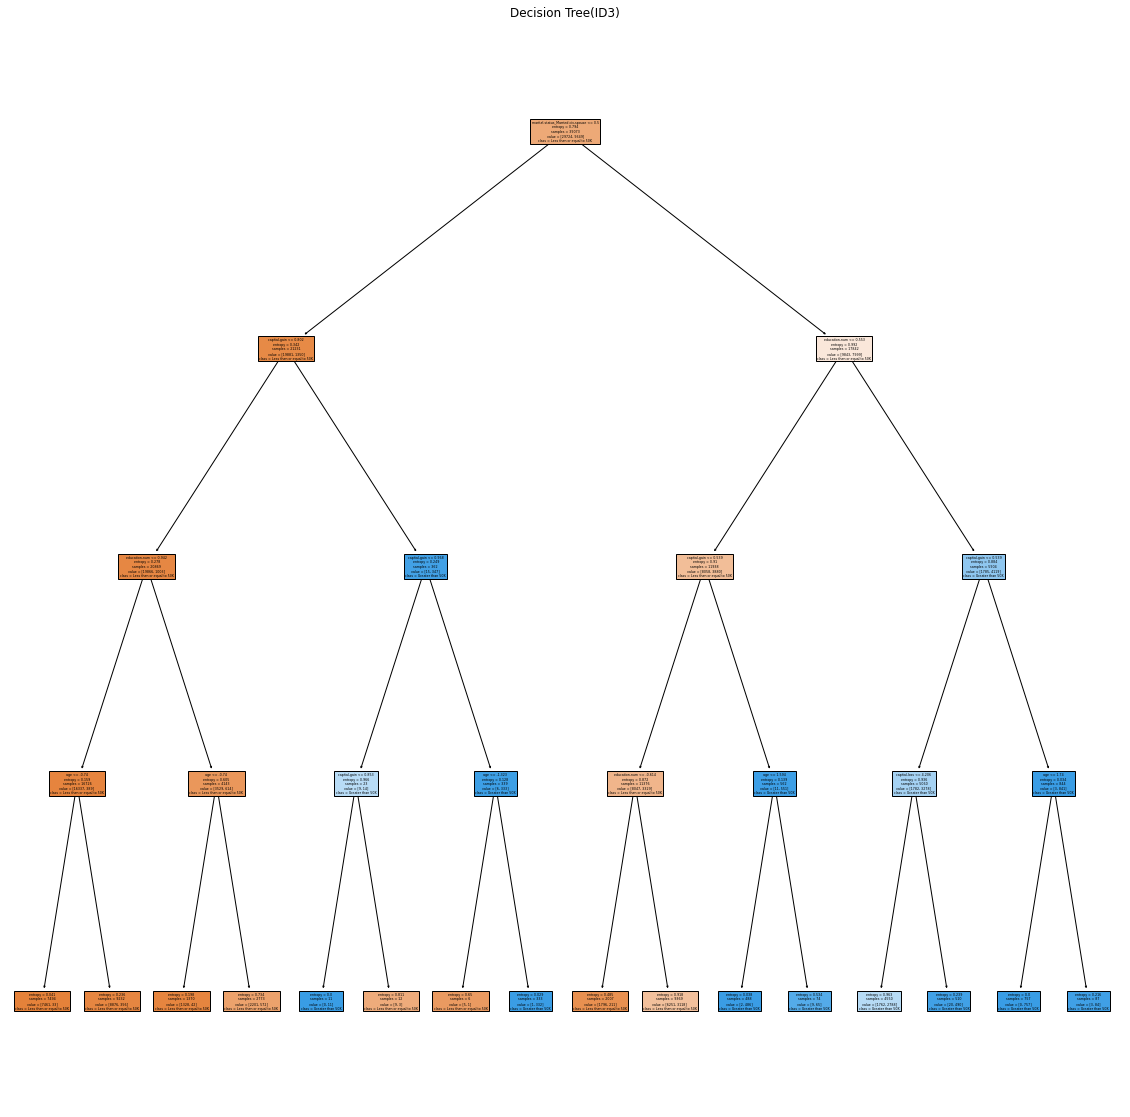

In [136]:
#tree plot
plt.figure(figsize=(20,20))
plot_tree(tree,feature_names=x_test.columns,class_names=['Less than or equal to 50K','Greater than 50K'],filled=True)
plt.title("Decision Tree(ID3)")
plt.show()